# Homework 7

## Setup
### Import Libraries

In [1]:
import copy
import random
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
from sklearn.model_selection import train_test_split
from IPython.display import display, Markdown

### Training Settings

In [2]:
SEED = 42
MAX_EPOCHS = 100
BATCH_SIZE = 256
LEARNING_RATE = 0.001
WEIGHT_DECAY = 0.0001
PATIENCE = 8
MIN_DELTA = 0.0001
HIDDEN_WIDTH = 256

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
Path('figures').mkdir(exist_ok=True)
print('Device:', device)
print('Maximum Epochs:', MAX_EPOCHS)
print('Batch Size:', BATCH_SIZE)
print('Learning Rate:', LEARNING_RATE)

Device: cpu
Maximum Epochs: 100
Batch Size: 256
Learning Rate: 0.001


### Load CIFAR-10 Dataset

In [3]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.4914, 0.4822, 0.4465),
                         (0.2470, 0.2435, 0.2616))
])

training_data = datasets.CIFAR10(root='data', train=True, download=True, transform=transform)
testing_data = datasets.CIFAR10(root='data', train=False, download=True, transform=transform)

train_indices, validation_indices = train_test_split(
    np.arange(len(training_data)), test_size=0.10,
    stratify=training_data.targets, random_state=SEED
)

training_set = Subset(training_data, train_indices)
validation_set = Subset(training_data, validation_indices)

NUM_WORKERS = 2 if device.type == 'cuda' else 0
loader_settings = {'num_workers': NUM_WORKERS, 'pin_memory': device.type == 'cuda'}

validation_loader = DataLoader(validation_set, batch_size=512, **loader_settings)
testing_loader = DataLoader(testing_data, batch_size=512, **loader_settings)
training_eval_loader = DataLoader(training_set, batch_size=512, **loader_settings)

print('Training Samples:', len(training_set))
print('Validation Samples:', len(validation_set))
print('Testing Samples:', len(testing_data))
print('Image Shape:', training_data[0][0].shape)
print('Classes:', len(training_data.classes))

100%|██████████| 170M/170M [17:40<00:00, 161kB/s]


Training Samples: 45000
Validation Samples: 5000
Testing Samples: 10000
Image Shape: torch.Size([3, 32, 32])
Classes: 10


### Helper Functions

In [4]:
def make_network(hidden_layers, activation):
    activations = {'ReLU': nn.ReLU, 'Sigmoid': nn.Sigmoid, 'Tanh': nn.Tanh}
    layers = [nn.Flatten()]
    inputs = 32 * 32 * 3

    for width in hidden_layers:
        layers.append(nn.Linear(inputs, width))
        layers.append(activations[activation]())
        inputs = width

    layers.append(nn.Linear(inputs, 10))
    return nn.Sequential(*layers)


def evaluate_model(model, data_loader, criterion):
    model.eval()
    loss_total = 0.0
    correct = 0
    total = 0

    with torch.inference_mode():
        for inputs, labels in data_loader:
            inputs = inputs.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)
            outputs = model(inputs)
            loss_total += criterion(outputs, labels).item() * len(labels)
            correct += (outputs.argmax(dim=1) == labels).sum().item()
            total += len(labels)

    return loss_total / total, correct / total


def train_experiment(name, hidden_layers, activation):
    torch.manual_seed(SEED)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED)

    model = make_network(hidden_layers, activation).to(device)
    parameters = sum(parameter.numel() for parameter in model.parameters() if parameter.requires_grad)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
    generator = torch.Generator().manual_seed(SEED)
    training_loader = DataLoader(
        training_set, batch_size=BATCH_SIZE, shuffle=True,
        generator=generator, **loader_settings
    )

    records = []
    best_loss = float('inf')
    best_epoch = 0
    best_weights = None
    stale_epochs = 0

    if device.type == 'cuda':
        torch.cuda.synchronize()
    start_time = time.perf_counter()

    for epoch in range(1, MAX_EPOCHS + 1):
        model.train()
        running_loss = 0.0
        correct = 0
        total = 0

        for inputs, labels in training_loader:
            inputs = inputs.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * len(labels)
            correct += (outputs.argmax(dim=1) == labels).sum().item()
            total += len(labels)

        validation_loss, validation_accuracy = evaluate_model(model, validation_loader, criterion)
        records.append({
            'Epoch': epoch,
            'Training Loss': running_loss / total,
            'Validation Loss': validation_loss,
            'Training Accuracy': correct / total,
            'Validation Accuracy': validation_accuracy
        })

        if validation_loss < best_loss - MIN_DELTA:
            best_loss = validation_loss
            best_epoch = epoch
            best_weights = copy.deepcopy(model.state_dict())
            stale_epochs = 0
        else:
            stale_epochs += 1

        if epoch == 1 or epoch % 10 == 0 or stale_epochs >= PATIENCE:
            print(f'{name} | Epoch {epoch:3d} | Training Loss: {running_loss / total:.4f} | Validation Loss: {validation_loss:.4f}')

        if stale_epochs >= PATIENCE:
            break

    if device.type == 'cuda':
        torch.cuda.synchronize()
    training_time = time.perf_counter() - start_time
    model.load_state_dict(best_weights)
    training_loss, training_accuracy = evaluate_model(model, training_eval_loader, criterion)
    _, test_accuracy = evaluate_model(model, testing_loader, criterion)

    return {
        'Model': name,
        'Hidden Layers': len(hidden_layers),
        'Neurons': ' × '.join(map(str, hidden_layers)),
        'Activation': activation,
        'Epochs Trained': len(records),
        'Selected Epoch': best_epoch,
        'Training Time (s)': training_time,
        'Training Loss': training_loss,
        'Training Accuracy': training_accuracy,
        'Evaluation Accuracy': test_accuracy,
        'Parameters': parameters,
        'History': pd.DataFrame(records)
    }


def results_table(models):
    columns = ['Model', 'Hidden Layers', 'Neurons', 'Activation', 'Epochs Trained',
               'Selected Epoch', 'Training Time (s)', 'Training Loss',
               'Training Accuracy', 'Evaluation Accuracy', 'Parameters']
    return pd.DataFrame([{key: item[key] for key in columns} for item in models]).round(4)


def plot_history(result):
    history = result['History']
    figure, axes = plt.subplots(1, 2, figsize=(12, 4))

    axes[0].plot(history['Epoch'], history['Training Loss'], label='Training')
    axes[0].plot(history['Epoch'], history['Validation Loss'], label='Validation')
    axes[0].set_xlabel('Epoch')
    axes[0].set_ylabel('Loss')
    axes[0].set_title('Loss')
    axes[0].legend()
    axes[0].grid(True)

    axes[1].plot(history['Epoch'], history['Training Accuracy'], label='Training')
    axes[1].plot(history['Epoch'], history['Validation Accuracy'], label='Validation')
    axes[1].set_xlabel('Epoch')
    axes[1].set_ylabel('Accuracy')
    axes[1].set_title('Accuracy')
    axes[1].legend()
    axes[1].grid(True)

    figure.suptitle(result['Model'])
    figure.tight_layout()
    figure.savefig(Path('figures') / (result['Model'].lower().replace(' ', '_') + '.png'), dpi=150)
    plt.show()

## Problem 1a
### Baseline Fully Connected Neural Network

In [5]:
baseline = train_experiment('Baseline', [HIDDEN_WIDTH, HIDDEN_WIDTH], 'ReLU')
display(results_table([baseline]))

Baseline | Epoch   1 | Training Loss: 1.6601 | Validation Loss: 1.5028
Baseline | Epoch  10 | Training Loss: 0.8217 | Validation Loss: 1.4920
Baseline | Epoch  13 | Training Loss: 0.6597 | Validation Loss: 1.5976


,Model,Hidden Layers,Neurons,Activation,Epochs Trained,Selected Epoch,Training Time (s),Training Loss,Training Accuracy,Evaluation Accuracy,Parameters
0,Baseline,2,256 × 256,ReLU,13,5,148.2567,1.032,0.6409,0.527,855050


### Training Loss and Accuracy

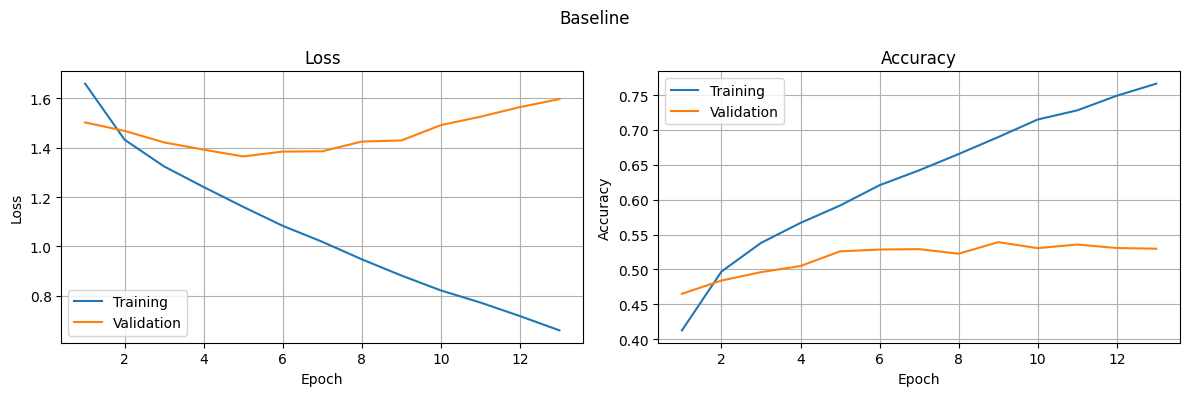

In [6]:
plot_history(baseline)

## Problem 1b
### Four Hidden Layers

In [7]:
four_layer = train_experiment('Four Hidden Layers', [HIDDEN_WIDTH] * 4, 'ReLU')
display(results_table([baseline, four_layer]))

Four Hidden Layers | Epoch   1 | Training Loss: 1.7078 | Validation Loss: 1.5431
Four Hidden Layers | Epoch  10 | Training Loss: 0.8392 | Validation Loss: 1.4728
Four Hidden Layers | Epoch  13 | Training Loss: 0.6727 | Validation Loss: 1.5844


,Model,Hidden Layers,Neurons,Activation,Epochs Trained,Selected Epoch,Training Time (s),Training Loss,Training Accuracy,Evaluation Accuracy,Parameters
0,Baseline,2,256 × 256,ReLU,13,5,148.2567,1.0320,0.6409,0.5270,855050
1,Four Hidden Layers,4,256 × 256 × 256 × 256,ReLU,13,5,155.2982,1.0632,0.6250,0.5232,986634


### Training Loss and Accuracy

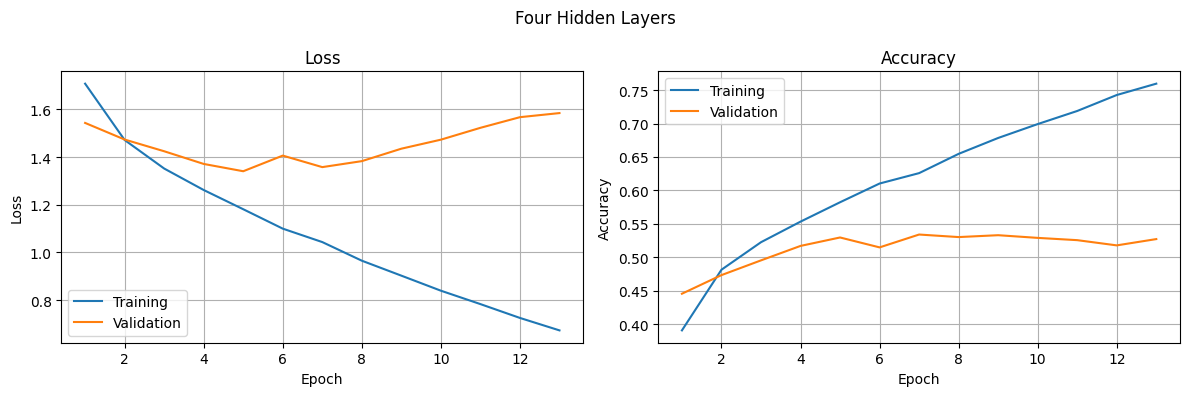

In [8]:
plot_history(four_layer)

## Problem 2a
### Ten Hidden Layers

In [9]:
ten_layer = train_experiment('Ten Hidden Layers', [HIDDEN_WIDTH] * 10, 'ReLU')
display(results_table([baseline, four_layer, ten_layer]))

Ten Hidden Layers | Epoch   1 | Training Loss: 2.0518 | Validation Loss: 1.9709
Ten Hidden Layers | Epoch  10 | Training Loss: 1.2232 | Validation Loss: 1.4393
Ten Hidden Layers | Epoch  20 | Training Loss: 0.8416 | Validation Loss: 1.6321
Ten Hidden Layers | Epoch  22 | Training Loss: 0.7844 | Validation Loss: 1.6068


,Model,Hidden Layers,Neurons,Activation,Epochs Trained,Selected Epoch,Training Time (s),Training Loss,Training Accuracy,Evaluation Accuracy,Parameters
0,Baseline,2,256 × 256,ReLU,13,5,148.2567,1.0320,0.6409,0.5270,855050
1,Four Hidden Layers,4,256 × 256 × 256 × 256,ReLU,13,5,155.2982,1.0632,0.6250,0.5232,986634
2,Ten Hidden Layers,10,256 × 256 × 256 × 256 × 256 × 256 × 256 × 256 ...,ReLU,22,14,295.4826,0.9934,0.6438,0.4958,1381386


### Training Loss and Accuracy

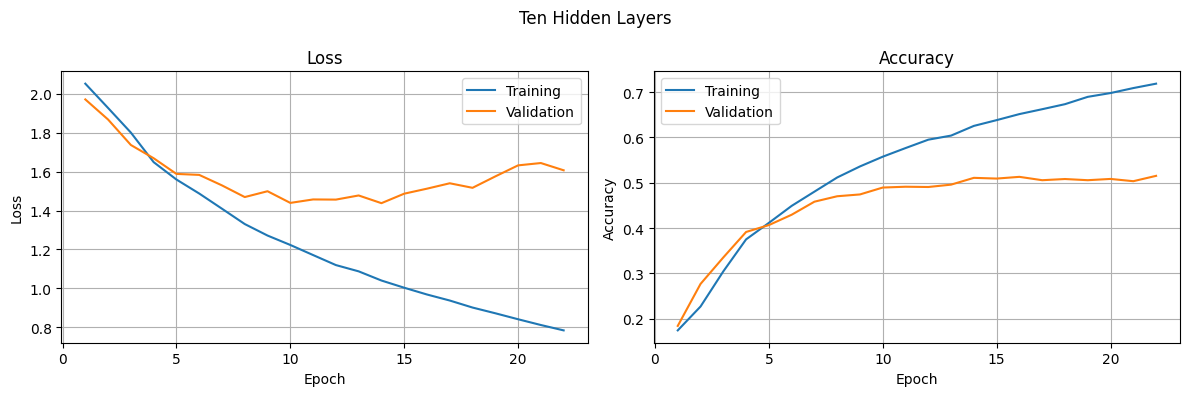

In [10]:
plot_history(ten_layer)

## Problem 2b
### Increasing Width

In [11]:
wide = train_experiment('Double Width', [HIDDEN_WIDTH * 2] * 2, 'ReLU')
display(results_table([baseline, wide]))

Double Width | Epoch   1 | Training Loss: 1.6538 | Validation Loss: 1.4883
Double Width | Epoch  10 | Training Loss: 0.7542 | Validation Loss: 1.5580
Double Width | Epoch  15 | Training Loss: 0.4729 | Validation Loss: 1.8139


,Model,Hidden Layers,Neurons,Activation,Epochs Trained,Selected Epoch,Training Time (s),Training Loss,Training Accuracy,Evaluation Accuracy,Parameters
0,Baseline,2,256 × 256,ReLU,13,5,148.2567,1.0320,0.6409,0.5270,855050
1,Double Width,2,512 × 512,ReLU,15,7,216.7028,0.8475,0.7084,0.5328,1841162


### Training Loss and Accuracy

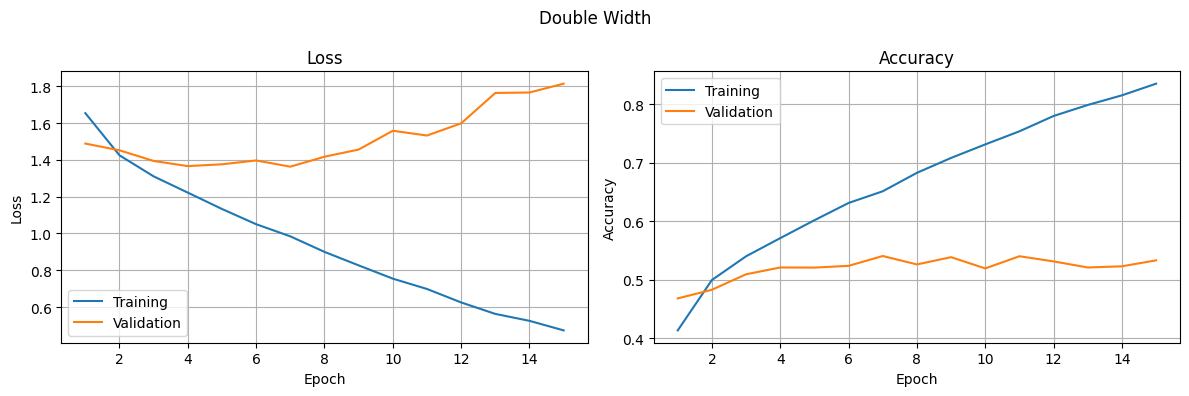

In [12]:
plot_history(wide)

### Sigmoid Activation

In [13]:
sigmoid = train_experiment('Sigmoid', [HIDDEN_WIDTH] * 2, 'Sigmoid')
display(results_table([baseline, sigmoid]))

Sigmoid | Epoch   1 | Training Loss: 1.8524 | Validation Loss: 1.7189
Sigmoid | Epoch  10 | Training Loss: 1.2637 | Validation Loss: 1.5247
Sigmoid | Epoch  20 | Training Loss: 0.9129 | Validation Loss: 1.6242


,Model,Hidden Layers,Neurons,Activation,Epochs Trained,Selected Epoch,Training Time (s),Training Loss,Training Accuracy,Evaluation Accuracy,Parameters
0,Baseline,2,256 × 256,ReLU,13,5,148.2567,1.032,0.6409,0.5270,855050
1,Sigmoid,2,256 × 256,Sigmoid,20,12,225.1244,1.108,0.6192,0.4798,855050


### Training Loss and Accuracy

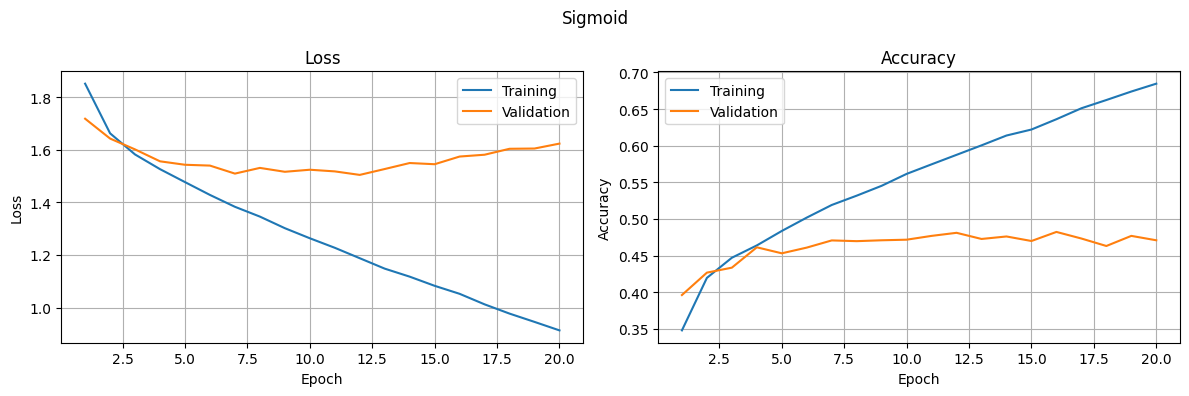

In [14]:
plot_history(sigmoid)

### Tanh Activation

In [15]:
tanh = train_experiment('Tanh', [HIDDEN_WIDTH] * 2, 'Tanh')
display(results_table([baseline, tanh]))

Tanh | Epoch   1 | Training Loss: 1.7902 | Validation Loss: 1.6831
Tanh | Epoch  10 | Training Loss: 1.3232 | Validation Loss: 1.5578
Tanh | Epoch  18 | Training Loss: 1.0588 | Validation Loss: 1.6163


,Model,Hidden Layers,Neurons,Activation,Epochs Trained,Selected Epoch,Training Time (s),Training Loss,Training Accuracy,Evaluation Accuracy,Parameters
0,Baseline,2,256 × 256,ReLU,13,5,148.2567,1.0320,0.6409,0.5270,855050
1,Tanh,2,256 × 256,Tanh,18,10,218.7964,1.2402,0.5698,0.4623,855050


### Training Loss and Accuracy

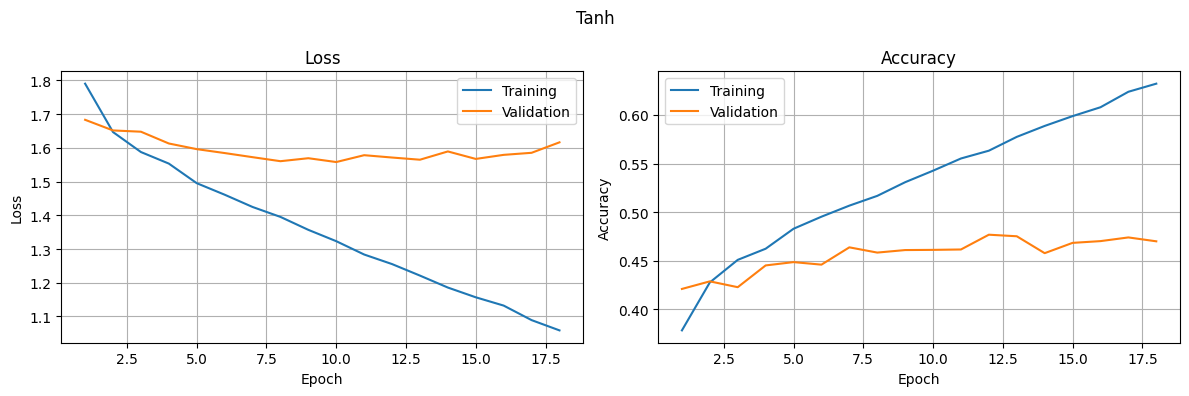

In [16]:
plot_history(tanh)

### Final Model Comparison

In [17]:
all_models = [baseline, four_layer, ten_layer, wide, sigmoid, tanh]
comparison = results_table(all_models)
display(comparison)

,Model,Hidden Layers,Neurons,Activation,Epochs Trained,Selected Epoch,Training Time (s),Training Loss,Training Accuracy,Evaluation Accuracy,Parameters
0,Baseline,2,256 × 256,ReLU,13,5,148.2567,1.0320,0.6409,0.5270,855050
1,Four Hidden Layers,4,256 × 256 × 256 × 256,ReLU,13,5,155.2982,1.0632,0.6250,0.5232,986634
2,Ten Hidden Layers,10,256 × 256 × 256 × 256 × 256 × 256 × 256 × 256 ...,ReLU,22,14,295.4826,0.9934,0.6438,0.4958,1381386
3,Double Width,2,512 × 512,ReLU,15,7,216.7028,0.8475,0.7084,0.5328,1841162
4,Sigmoid,2,256 × 256,Sigmoid,20,12,225.1244,1.1080,0.6192,0.4798,855050
5,Tanh,2,256 × 256,Tanh,18,10,218.7964,1.2402,0.5698,0.4623,855050


### Accuracy Comparison

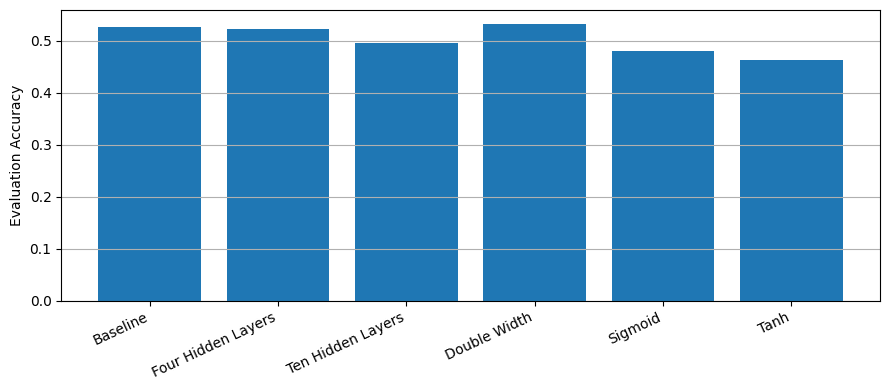

In [18]:
plt.figure(figsize=(9, 4))
plt.bar(comparison['Model'], comparison['Evaluation Accuracy'])
plt.ylabel('Evaluation Accuracy')
plt.xticks(rotation=25, ha='right')
plt.grid(axis='y')
plt.tight_layout()
plt.savefig('figures/evaluation_accuracy_comparison.png', dpi=150)
plt.show()